# Gradient forest: *P. guttatus*

Fit SNP-specific forests using the example VCF, sample coordinates and 19 bioclim rasters, then map environmental turnover.

Install from the repository root with `python -m pip install -e ".[notebook]"`. Run this notebook from `notebooks/` using that environment.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pygf import GradientForest, read_coordinates, read_vcf, sample_environment

## Read samples and genotypes

`read_coordinates` returns a GeoDataFrame from the headerless sample, longitude, latitude file. `read_vcf` returns an xarray Dataset of alternate-allele dosages (0, 1, 2), with missing calls as NaN.

Keep SNPs with call rate ≥ 80% and minor allele frequency ≥ 5%, then sample 256 across the file. `one_per_contig=True` keeps one eligible SNP per RAD contig; use `False` for whole-chromosome data. Set `max_variants=None` to keep all eligible SNPs. Plain and gzipped VCFs are supported.

`samples=sites` returns genotypes in coordinate-file order. Climate rows preserve the same order, so `sites`, `X` and `y` stay aligned.

<Axes: >

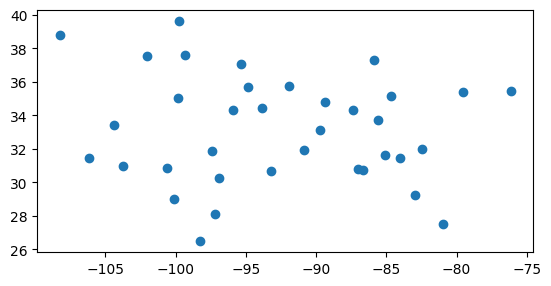

In [2]:
sites = read_coordinates("../examples/Pguttatus_coords.txt")
genotypes = read_vcf(
    "../examples/Pguttatus.vcf",
    samples=sites,
    min_call_rate=0.8,
    min_maf=0.05,
    one_per_contig=True,
    max_variants=256,
    random_state=42,
)
sites.plot()

## Sample climate

`sample_environment` takes the bioclim directory, opens a bounding box around the sites with 20% of its width/height added on each side, and extracts native-resolution values in coordinate-file order. It reprojects sites to the raster CRS and closes the rasters after sampling. Use `variables=["bio1", "bio12"]` to select layers or `buffer=0.1` for a smaller region.

Missing climate values remain NaN. `drop_missing=True` removes incomplete rows; if used, align the other inputs to those remaining IDs once before fitting. The example retains all 36 sites.

In [3]:
X = sample_environment("../envs", sites)
y = genotypes.dosage.to_pandas()
X.head()

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
LSU99213,19.115833,11.865000,40.417633,676.937683,33.139999,3.784,29.355999,11.547334,15.234667,27.132000,10.488000,1478.0,158.0,92.0,14.483758,418.0,320.0,366.0,405.0
OMNH9224,15.792167,15.137000,37.766968,913.650269,35.743999,-4.336,40.079998,20.497334,4.397333,26.977333,4.397333,626.0,104.0,17.0,52.633015,247.0,62.0,198.0,62.0
OMNH8361,15.129333,12.856667,37.627800,792.639038,32.000000,-2.168,34.167999,14.956667,5.099333,24.677999,5.099333,1509.0,169.0,86.0,19.535410,470.0,323.0,337.0,323.0
FLMNH153506,18.062166,13.024334,41.315613,711.381104,33.180000,1.656,31.524000,10.619333,23.122667,26.576666,9.070666,1488.0,162.0,88.0,20.799999,443.0,273.0,307.0,430.0
FLMNH151609,15.625667,17.631334,44.424850,837.177002,35.023998,-4.664,39.688000,25.017332,7.156667,25.798000,5.204000,332.0,62.0,8.0,66.924088,162.0,27.0,151.0,32.0


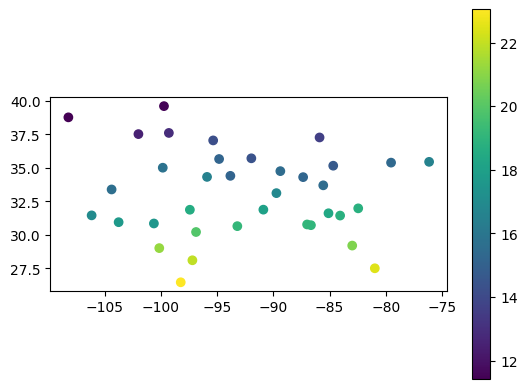

In [4]:
sites.plot(column=X.bio1, legend=True);

## Fit and inspect

Each SNP uses its observed genotypes. Only responses with positive out-of-bag (OOB) R² and permutation importance contribute to turnover.

`max_level=2` uses approximate conditional permutations for correlated predictors; `max_level=0` gives marginal permutations. `corr_threshold` sets the correlation cutoff. Other options control tree size (`max_features`, `min_samples_leaf`, `max_depth`), curve resolution (`n_bins`), permutation repeats (`n_permutations`), minimum skill (`min_oob_r2`), density correction (`density_correction`) and tree parallelism (`n_jobs`).

In [5]:
gf = GradientForest(
    n_estimators=100, max_level=2, random_state=42, keep_response_curves=True,
).fit(X, y)
gf.response_scores_.sort_values("oob_r2", ascending=False).head()

,n_observed,oob_r2,oob_coverage,retained,reason
response,,,,,
RAD_11467:26:C:A,33,0.817141,1.0,True,retained
RAD_49550:52:C:T,30,0.805833,1.0,True,retained
RAD_44571:22:A:G,30,0.799256,1.0,True,retained
RAD_18759:57:T:C,31,0.732192,1.0,True,retained
RAD_47312:19:G:A,29,0.702978,1.0,True,retained


`response_scores_` records OOB skill and inclusion for every SNP; `oob_predictions_` holds its OOB predictions. `permutation_importances_` contains raw MSE increases and `response_importances_` contains allocated R². Set `keep_forests=True` to retain fitted trees in `forests_`.

`importance_` ranks predictors by mean allocated R²; `feature_importances_` contains the same values in input order.

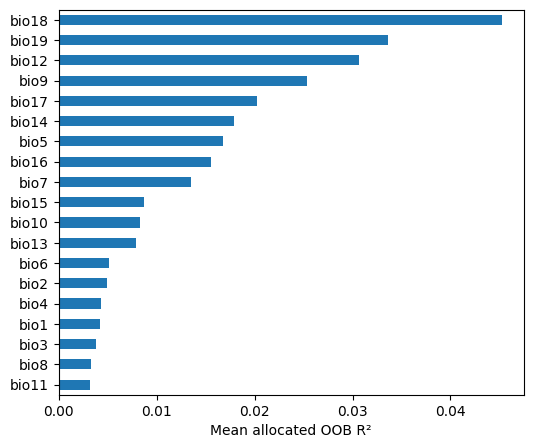

In [6]:
gf.importance_.sort_values().plot.barh(figsize=(6, 5), xlabel="Mean allocated OOB R²");

## Turnover curves and transformed samples

`turnover_` contains a cumulative curve for each predictor. Steep sections indicate rapid turnover; endpoints give predictor importance. `transform` returns these turnover coordinates, preserving sample IDs. `predict` is an alias; `fit_transform(X, y)` combines fitting and transformation.

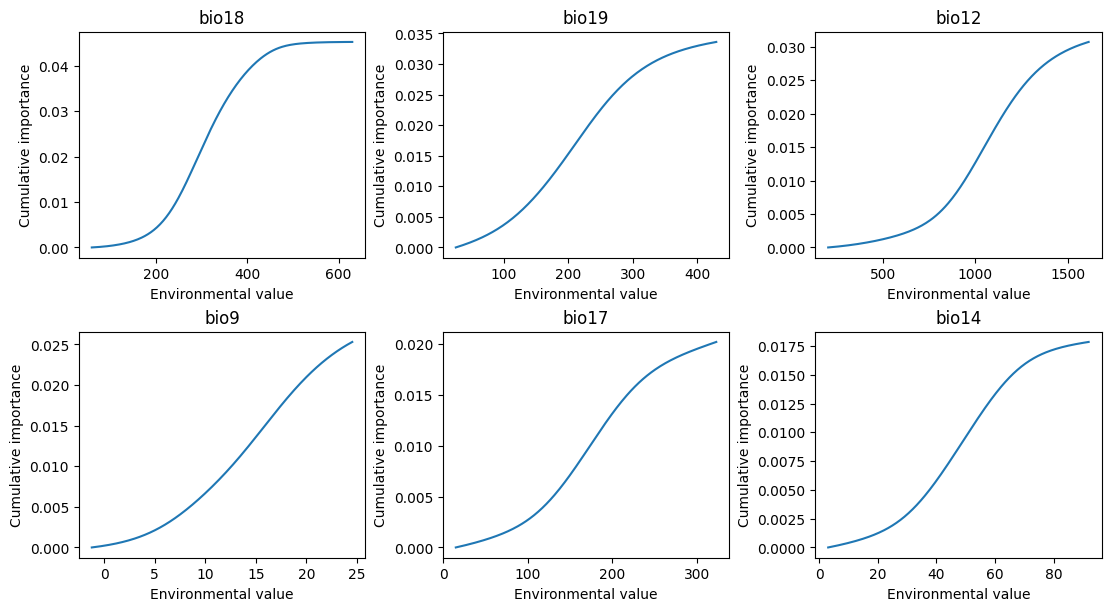

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
for ax, name in zip(axes.flat, gf.importance_.head(6).index):
    curve = gf.turnover_[name]
    ax.plot(curve.value, curve.cumulative_importance)
    ax.set(title=name, xlabel="Environmental value", ylabel="Cumulative importance")
plt.show()

In [8]:
turnover = gf.transform(X)
turnover.head()

,bio1,bio2,bio3,bio4,bio5,bio6,bio7,bio8,bio9,bio10,bio11,bio12,bio13,bio14,bio15,bio16,bio17,bio18,bio19
sample,,,,,,,,,,,,,,,,,,,
LSU99213,0.001264,0.000262,0.002802,0.001081,0.005533,0.003754,0.001302,0.000689,0.013956,0.002156,0.001846,0.029189,0.006565,0.017847,0.000000,0.012279,0.020109,0.034274,0.033076
OMNH9224,0.000495,0.003956,0.002052,0.003487,0.015673,0.001304,0.012849,0.002144,0.001751,0.001987,0.000706,0.002219,0.002290,0.000936,0.007689,0.002164,0.001097,0.004028,0.001456
OMNH8361,0.000409,0.000877,0.002002,0.002110,0.001771,0.002079,0.005986,0.001312,0.002168,0.000430,0.000824,0.029610,0.007012,0.017574,0.000972,0.014074,0.020195,0.029330,0.029731
FLMNH153506,0.000909,0.000998,0.002989,0.001385,0.005698,0.003167,0.002735,0.000524,0.024237,0.001645,0.001516,0.029331,0.006743,0.017675,0.001251,0.013265,0.018556,0.023170,0.033607
FLMNH151609,0.000473,0.004937,0.003448,0.002573,0.013695,0.001180,0.012673,0.002941,0.003738,0.001125,0.000841,0.000383,0.000260,0.000275,0.008377,0.000468,0.000235,0.001436,0.000238


## Map turnover

`plot_turnover()` uses the directory and sites remembered from `sample_environment`, opens the same buffered region, transforms it, and overlays the sites. It defaults to the most important predictor; pass a name such as `"bio1"` to choose another. Directory maps use every fourth cell by default (`stride=1` keeps native resolution).

The result exposes `.figure`, `.ax` and a computed xarray `.turnover` Dataset for export. `transform_raster` remains available for custom xarray grids; missing pixels are masked and values outside training ranges are clamped.

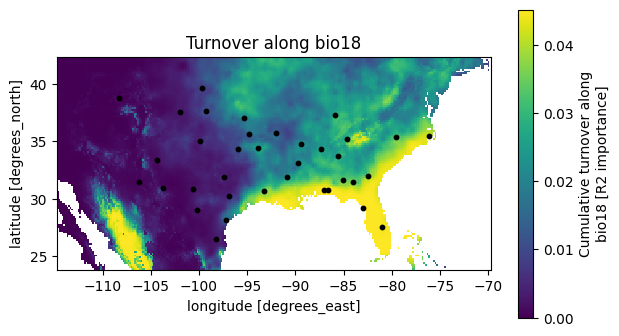

In [9]:
turnover_map = gf.plot_turnover()  # Or gf.plot_turnover("bio1")

## Spatial turnover and environmental biplots

The map and biplot share colours from the first three PCs of GF-transformed environments. Pass the bioclim directory; site bounds, the 20% buffer and downsampling are handled internally. PCA uses the resulting region without standardizing predictors, so GF importance weights are preserved. Labelled arrows show the largest environmental covariance loadings in PC1/2: direction indicates increasing values and relative length indicates contribution to the displayed pattern.

`response=None` uses all contributing SNPs. Pass a SNP name for its own turnover curves (requires `keep_response_curves=True` when fitting). `n_vectors` controls labelled arrows; `label_sites=True` adds sample IDs; `inset=True` places the biplot inside the map. Omit `environment` for a PCA of sample locations alone.

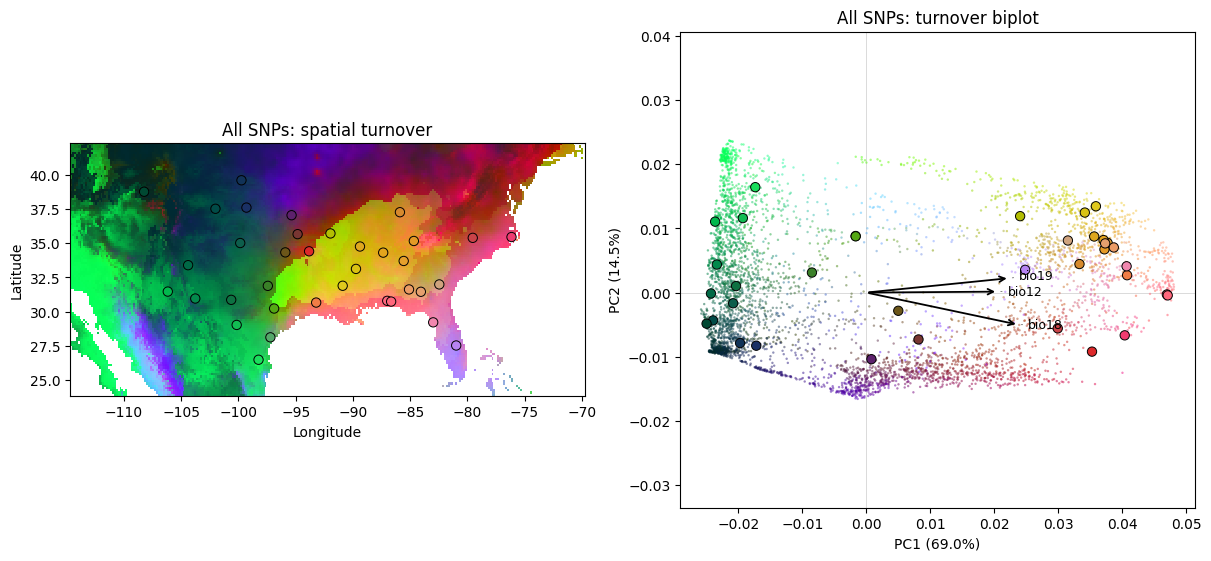

In [10]:
biplot = gf.plot_biplot(X, sites, environment="../envs", n_vectors=3)

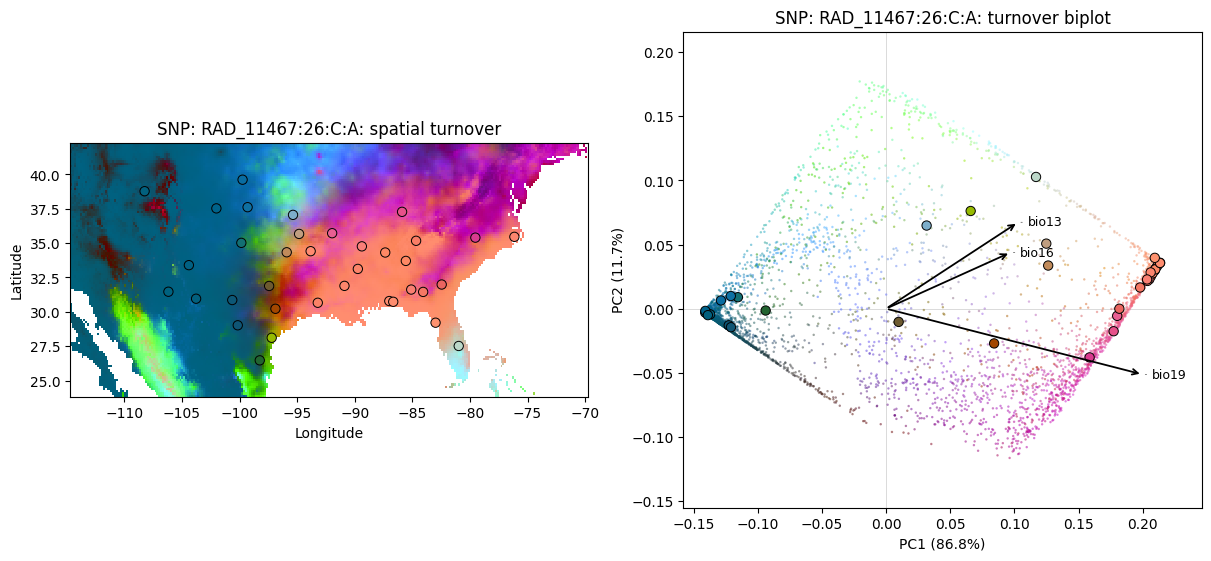

In [11]:
snp = gf.response_scores_.oob_r2.idxmax()
snp_biplot = gf.plot_biplot(X, sites, environment="../envs", response=snp, n_vectors=3)

`biplot.scores`, `.vectors` and `.colors` contain the numerical results; `.rgb` is the georeferenced map colour array. Each SNP has its own PCA/colour scale. These plots summarize predicted turnover, not predicted allele frequencies. This example uses individuals; for population-level composition, fit population allele frequencies against population-level environments and supply population locations.

## Export

Save diagnostics, sample coordinates, curves and a GeoTIFF with one named band per predictor.

In [12]:
Path("outputs").mkdir(exist_ok=True)
gf.response_scores_.to_csv("outputs/snp_oob_scores.csv")
gf.importance_.to_csv("outputs/predictor_importance.csv")
turnover.to_csv("outputs/sample_turnover.csv")
pd.concat(gf.turnover_, names=["predictor", "bin"]).to_csv("outputs/turnover_curves.csv")

bands = turnover_map.turnover.to_array("band").rio.write_nodata(np.nan)
bands.attrs["long_name"] = tuple(X.columns)
bands.rio.to_raster("outputs/genomic_turnover.tif", compress="deflate", dtype="float32")
turnover_map.figure.savefig("outputs/turnover_map.png", dpi=150, bbox_inches="tight")
biplot.figure.savefig("outputs/turnover_biplot.png", dpi=150, bbox_inches="tight")
snp_biplot.figure.savefig("outputs/snp_biplot.png", dpi=150, bbox_inches="tight")

These are individual genotype responses, not population allele frequencies. OOB skill and turnover alone do not establish adaptation or spatial transfer accuracy. Conditional permutations and smoothing differ from R gradientForest; see the [README](../README.md) for method details and [Ellis et al. (2012)](https://doi.org/10.1890/11-0252.1) for the original method.